# LMS: KPIs and Management Reports

All results come straight from the MySQL database.

In [1]:
from db import run_query

## Dashboard KPIs

In [2]:
run_query("""
    SELECT (SELECT COUNT(*) FROM students) AS students,
           (SELECT COUNT(*) FROM students WHERE status = 'Active') AS active_students,
           (SELECT COUNT(*) FROM instructors) AS instructors,
           (SELECT COUNT(*) FROM courses) AS courses,
           (SELECT COUNT(*) FROM enrollments) AS enrollments
""")

,students,active_students,instructors,courses,enrollments
0,20,16,5,7,37


## BR-01: Which courses have the most students?

In [3]:
popularity = run_query("""
    SELECT c.course_name, COUNT(e.enrollment_id) AS enrolled_students
    FROM courses c
    INNER JOIN enrollments e ON e.course_id = c.course_id
    WHERE e.status <> 'Dropped'
    GROUP BY c.course_id, c.course_name
    ORDER BY enrolled_students DESC
""")
popularity

,course_name,enrolled_students
0,Python Programming,12
1,MySQL Database Design,6
2,Data Analysis with Pandas,5
3,Machine Learning Fundamentals,4
4,Web Development Basics,4
5,Digital Marketing,1


<Axes: xlabel='course_name'>

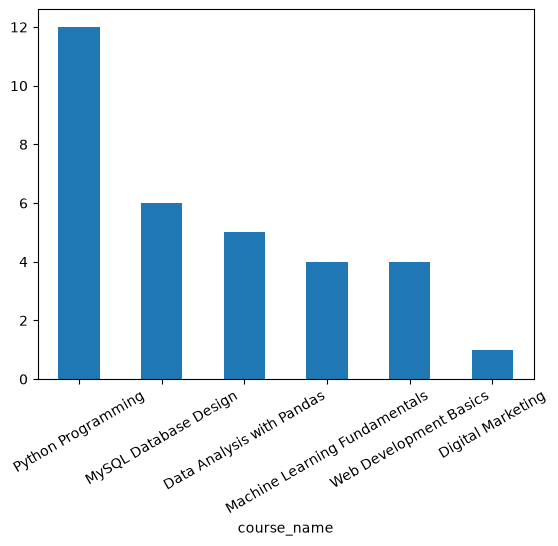

In [4]:
popularity.plot.bar(x="course_name", y="enrolled_students", legend=False, rot=30)

## BR-02: How many courses does each instructor teach?

In [5]:
workload = run_query("""
    SELECT i.full_name AS instructor, COUNT(c.course_id) AS courses_taught
    FROM instructors i
    LEFT JOIN courses c ON c.instructor_id = i.instructor_id
    GROUP BY i.instructor_id, i.full_name
    ORDER BY courses_taught DESC, i.full_name
""")
workload

,instructor,courses_taught
0,Dr. Imran Shah,2
1,Mr. Kamran Akbar,2
2,Ms. Sadia Malik,2
3,Dr. Nadia Hussain,1
4,Mr. Tariq Mehmood,0


## BR-03: Which students have the highest total marks?

In [6]:
top_students = run_query("""
    SELECT s.full_name AS student, SUM(g.total_marks) AS total_marks,
           ROUND(SUM(g.total_marks) / COUNT(g.grade_id), 1) AS average_per_course
    FROM students s
    INNER JOIN enrollments e ON e.student_id = s.student_id
    INNER JOIN grades g ON g.enrollment_id = e.enrollment_id
    GROUP BY s.student_id, s.full_name
    ORDER BY total_marks DESC
    LIMIT 10
""")
top_students

,student,total_marks,average_per_course
0,Noor Fatima,166.0,83.0
1,Saad Mehmood,163.0,81.5
2,Sana Javed,162.0,81.0
3,Usman Ghani,148.0,74.0
4,Fatima Zahra,146.0,73.0
5,Bilal Ahmad,145.0,72.5
6,Hassan Ali,144.0,72.0
7,Hira Nawaz,141.0,70.5
8,Ali Hamza,141.0,70.5
9,Ahmed Raza,140.0,70.0


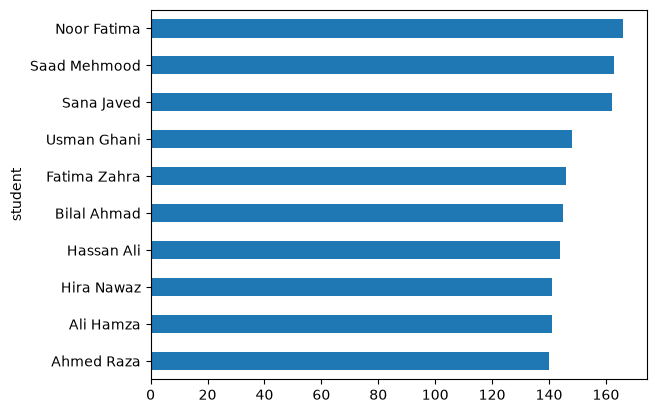

In [7]:
top_students.plot.barh(x="student", y="total_marks", legend=False).invert_yaxis()

## BR-04: How many students are active?

In [8]:
run_query("SELECT COUNT(*) AS active_students FROM students WHERE status = 'Active'")

,active_students
0,16


## BR-05: How many enrollments are Enrolled, Completed or Dropped?

In [9]:
status_counts = run_query("SELECT status, COUNT(*) AS total FROM enrollments GROUP BY status ORDER BY total DESC")
status_counts

,status,total
0,Enrolled,21
1,Completed,11
2,Dropped,5


<Axes: xlabel='status'>

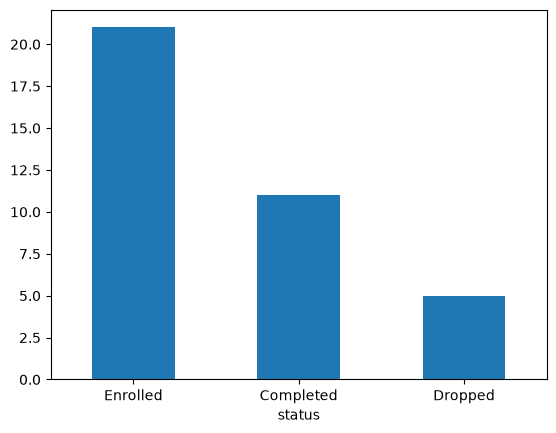

In [10]:
status_counts.plot.bar(x="status", y="total", legend=False, rot=0)

## BR-06: Which courses have no students enrolled?

In [11]:
run_query("""
    SELECT c.course_id, c.course_name
    FROM courses c
    LEFT JOIN enrollments e ON e.course_id = c.course_id
    WHERE e.enrollment_id IS NULL
""")

,course_id,course_name
0,7,Cloud Computing Basics


## Instructor workload

In [12]:
run_query("""
    SELECT i.full_name AS instructor,
           COUNT(DISTINCT c.course_id) AS courses,
           COUNT(e.enrollment_id) AS students_taught
    FROM instructors i
    LEFT JOIN courses c ON c.instructor_id = i.instructor_id
    LEFT JOIN enrollments e ON e.course_id = c.course_id AND e.status <> 'Dropped'
    GROUP BY i.instructor_id, i.full_name
    ORDER BY students_taught DESC
""")

,instructor,courses,students_taught
0,Dr. Imran Shah,2,16
1,Ms. Sadia Malik,2,11
2,Mr. Kamran Akbar,2,4
3,Dr. Nadia Hussain,1,1
4,Mr. Tariq Mehmood,0,0


## Student performance

In [13]:
run_query("""
    SELECT s.full_name AS student, c.course_name AS course, g.total_marks,
           CASE
               WHEN g.total_marks >= 85 THEN 'A'
               WHEN g.total_marks >= 70 THEN 'B'
               WHEN g.total_marks >= 55 THEN 'C'
               WHEN g.total_marks >= 40 THEN 'D'
               ELSE 'F'
           END AS grade
    FROM grades g
    INNER JOIN enrollments e ON e.enrollment_id = g.enrollment_id
    INNER JOIN students s ON s.student_id = e.student_id
    INNER JOIN courses c ON c.course_id = e.course_id
    ORDER BY g.total_marks DESC
""")

,student,course,total_marks,grade
0,Faisal Mahmood,Data Analysis with Pandas,92.0,A
1,Sana Javed,Web Development Basics,88.0,A
2,Saad Mehmood,MySQL Database Design,85.0,A
3,Noor Fatima,MySQL Database Design,85.0,A
4,Rabia Anwar,Machine Learning Fundamentals,83.0,B
5,Ali Hamza,Web Development Basics,81.0,B
6,Noor Fatima,Digital Marketing,81.0,B
7,Saad Mehmood,Data Analysis with Pandas,78.0,B
8,Ahmed Raza,Python Programming,77.0,B
9,Hira Nawaz,Python Programming,76.0,B


## Fee income per course

In [14]:
run_query("""
    SELECT c.course_name, COUNT(e.enrollment_id) AS students, SUM(c.fee) AS total_fee
    FROM courses c
    INNER JOIN enrollments e ON e.course_id = c.course_id
    WHERE e.status <> 'Dropped'
    GROUP BY c.course_id, c.course_name
    ORDER BY total_fee DESC
""")

,course_name,students,total_fee
0,Python Programming,12,300000.0
1,Machine Learning Fundamentals,4,180000.0
2,Data Analysis with Pandas,5,140000.0
3,MySQL Database Design,6,132000.0
4,Web Development Basics,4,120000.0
5,Digital Marketing,1,18000.0
